In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error , mean_squared_error , r2_score
from scipy import stats

sns.set_style("whitegrid")
pd.set_option("display.max_columns",50)
pd.set_option("display.float_format","{:.2f}".format)

print("Libraries loaded.")

Libraries loaded.


In [2]:
# 1. CSV read karein (r ke sath bina space ke)
df_raw = pd.read_csv(r"C:\Users\HP\Downloads\bikes.csv")

# 2. Data ko screen par dekhne ke liye
df_raw.head()

,model_name,model_year,kms_driven,owner,location,mileage,power,price
0,Bajaj Avenger Cruise 220 2017,2017,17000 Km,first owner,hyderabad,\n\n 35 kmpl,19 bhp,63500
1,Royal Enfield Classic 350cc 2016,2016,50000 Km,first owner,hyderabad,\n\n 35 kmpl,19.80 bhp,115000
2,Hyosung GT250R 2012,2012,14795 Km,first owner,hyderabad,\n\n 30 kmpl,28 bhp,300000
3,Bajaj Dominar 400 ABS 2017,2017,Mileage 28 Kms,first owner,pondicherry,\n\n 28 Kms,34.50 bhp,100000
4,Jawa Perak 330cc 2020,2020,2000 Km,first owner,bangalore,\n\n,30 bhp,197500


In [3]:
df_raw['owner'].unique()

<StringArray>
['first owner', 'third owner', 'second owner', 'fourth owner or more']
Length: 4, dtype: str

In [4]:
df_raw.dtypes

model_name      str
model_year    int64
kms_driven      str
owner           str
location        str
mileage         str
power           str
price         int64
dtype: object

In [5]:
df_raw.duplicated().sum

<bound method Series.sum of 0       False
1       False
2       False
3       False
4       False
        ...  
7852    False
7853    False
7854    False
7855    False
7856    False
Length: 7857, dtype: bool>

In [6]:
df_raw.isnull().sum()

model_name     0
model_year     0
kms_driven     0
owner          0
location      19
mileage       11
power         31
price          0
dtype: int64

In [7]:
df_raw['price'].describe()

count      7857.00
mean     106791.34
std      138926.12
min           0.00
25%       42000.00
50%       75000.00
75%      125000.00
max     3000000.00
Name: price, dtype: float64

In [8]:
df_raw[['kms_driven','mileage','power']]

,kms_driven,mileage,power
0,17000 Km,\n\n 35 kmpl,19 bhp
1,50000 Km,\n\n 35 kmpl,19.80 bhp
2,14795 Km,\n\n 30 kmpl,28 bhp
3,Mileage 28 Kms,\n\n 28 Kms,34.50 bhp
4,2000 Km,\n\n,30 bhp
...,...,...,...
7852,7000 Km,\n\n 42 kmpl,16 bhp
7853,Mileage 80 Kmpl,\n\n 80 Kmpl,7.7
7854,6407 Km,\n\n 65 kmpl,17 bhp
7855,7524 Km,\n\n 57 kmpl,11.80 bhp


In [9]:
def get_number(value):
    if pd.isna(value,):
        return np.nan
    value=value.replace(',','')
    number = ''
    dot_used = False

    for i in value:
        if i.isdigit():
            number+=i
        elif i == '.' and not dot_used:
            dot_used = True
        elif number:
            break
    return float(number) if number else np.nan

In [10]:
column_name = ['mileage', 'power', 'kms_driven']
for i in column_name:
    df_raw[i] = df_raw[i].apply(get_number)

In [11]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7857 entries, 0 to 7856
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   model_name  7857 non-null   str    
 1   model_year  7857 non-null   int64  
 2   kms_driven  7854 non-null   float64
 3   owner       7857 non-null   str    
 4   location    7838 non-null   str    
 5   mileage     7083 non-null   float64
 6   power       7826 non-null   float64
 7   price       7857 non-null   int64  
dtypes: float64(3), int64(2), str(3)
memory usage: 491.2 KB


In [12]:
df_raw.duplicated().sum()

np.int64(0)

In [13]:
df = df_raw.dropna(subset='price')


In [14]:
df

,model_name,model_year,kms_driven,owner,location,mileage,power,price
0,Bajaj Avenger Cruise 220 2017,2017,17000.00,first owner,hyderabad,35.00,19.00,63500
1,Royal Enfield Classic 350cc 2016,2016,50000.00,first owner,hyderabad,35.00,1980.00,115000
2,Hyosung GT250R 2012,2012,14795.00,first owner,hyderabad,30.00,28.00,300000
3,Bajaj Dominar 400 ABS 2017,2017,28.00,first owner,pondicherry,28.00,3450.00,100000
4,Jawa Perak 330cc 2020,2020,2000.00,first owner,bangalore,NaN,30.00,197500
...,...,...,...,...,...,...,...,...
7852,Yamaha YZF-R15 150cc 2011,2011,7000.00,first owner,agra,42.00,16.00,55000
7853,Bajaj Discover 100cc 2015,2015,80.00,first owner,delhi,80.00,77.00,28000
7854,Bajaj Pulsar 180cc 2016,2016,6407.00,first owner,bangalore,65.00,17.00,61740
7855,Bajaj V15 150cc 2016,2016,7524.00,first owner,bangalore,57.00,1180.00,49000


In [15]:
df[df['price']>0]

,model_name,model_year,kms_driven,owner,location,mileage,power,price
0,Bajaj Avenger Cruise 220 2017,2017,17000.00,first owner,hyderabad,35.00,19.00,63500
1,Royal Enfield Classic 350cc 2016,2016,50000.00,first owner,hyderabad,35.00,1980.00,115000
2,Hyosung GT250R 2012,2012,14795.00,first owner,hyderabad,30.00,28.00,300000
3,Bajaj Dominar 400 ABS 2017,2017,28.00,first owner,pondicherry,28.00,3450.00,100000
4,Jawa Perak 330cc 2020,2020,2000.00,first owner,bangalore,NaN,30.00,197500
...,...,...,...,...,...,...,...,...
7852,Yamaha YZF-R15 150cc 2011,2011,7000.00,first owner,agra,42.00,16.00,55000
7853,Bajaj Discover 100cc 2015,2015,80.00,first owner,delhi,80.00,77.00,28000
7854,Bajaj Pulsar 180cc 2016,2016,6407.00,first owner,bangalore,65.00,17.00,61740
7855,Bajaj V15 150cc 2016,2016,7524.00,first owner,bangalore,57.00,1180.00,49000


In [16]:
df = df[df['price']>0]

In [17]:
pd.Timestamp.today().year

2026

In [18]:
if 'model_year' in df.columns:
    current_year = pd.Timestamp.today().year
    df['model_year']=df['model_year'].between(1998,current_year)

In [19]:
df

,model_name,model_year,kms_driven,owner,location,mileage,power,price
0,Bajaj Avenger Cruise 220 2017,True,17000.00,first owner,hyderabad,35.00,19.00,63500
1,Royal Enfield Classic 350cc 2016,True,50000.00,first owner,hyderabad,35.00,1980.00,115000
2,Hyosung GT250R 2012,True,14795.00,first owner,hyderabad,30.00,28.00,300000
3,Bajaj Dominar 400 ABS 2017,True,28.00,first owner,pondicherry,28.00,3450.00,100000
4,Jawa Perak 330cc 2020,True,2000.00,first owner,bangalore,NaN,30.00,197500
...,...,...,...,...,...,...,...,...
7852,Yamaha YZF-R15 150cc 2011,True,7000.00,first owner,agra,42.00,16.00,55000
7853,Bajaj Discover 100cc 2015,True,80.00,first owner,delhi,80.00,77.00,28000
7854,Bajaj Pulsar 180cc 2016,True,6407.00,first owner,bangalore,65.00,17.00,61740
7855,Bajaj V15 150cc 2016,True,7524.00,first owner,bangalore,57.00,1180.00,49000


In [ ]:
#Create bike age and handle missing value

if "model_year" in df.columns:
    current_year = pd.Timestamp.today().year
    df["bike_age"] = current_year - df["model_year"]

if "location" in df.columns:
    df["location"] = df["location"]

In [26]:
df_clean = df.copy()
df_clean.to_csv("bikes_cleaned.csv" , index=False)

print("Cleaned dataset saved as bikes_cleaned.csv ")
display(df_clean.head)

Cleaned dataset saved as bikes_cleaned.csv 


<bound method NDFrame.head of                             model_name  model_year  kms_driven        owner  \
0        Bajaj Avenger Cruise 220 2017        True    17000.00  first owner   
1     Royal Enfield Classic 350cc 2016        True    50000.00  first owner   
2                  Hyosung GT250R 2012        True    14795.00  first owner   
3           Bajaj Dominar 400 ABS 2017        True       28.00  first owner   
4                Jawa Perak 330cc 2020        True     2000.00  first owner   
...                                ...         ...         ...          ...   
7852         Yamaha YZF-R15 150cc 2011        True     7000.00  first owner   
7853         Bajaj Discover 100cc 2015        True       80.00  first owner   
7854           Bajaj Pulsar 180cc 2016        True     6407.00  first owner   
7855              Bajaj V15 150cc 2016        True     7524.00  first owner   
7856           Bajaj Pulsar 220cc 2016        True    15000.00  first owner   

         location  mi

In [27]:
df_clean['price'].describe()

count      7826.00
mean     107214.35
std      139038.02
min        2000.00
25%       42500.00
50%       75000.00
75%      125000.00
max     3000000.00
Name: price, dtype: float64

In [28]:
df_clean['price'].skew()

np.float64(6.214268795526774)

<Axes: xlabel='price', ylabel='Count'>

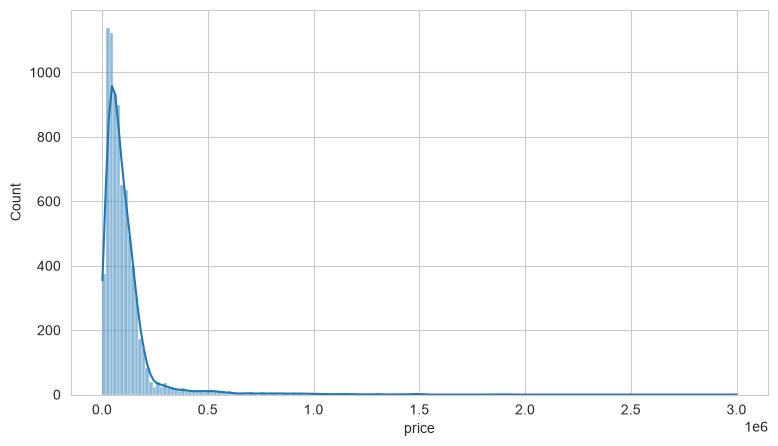

In [32]:
plt.figure(figsize=(9,5))
sns.histplot(data=df_clean,x='price',kde=True)

<Axes: xlabel='price'>

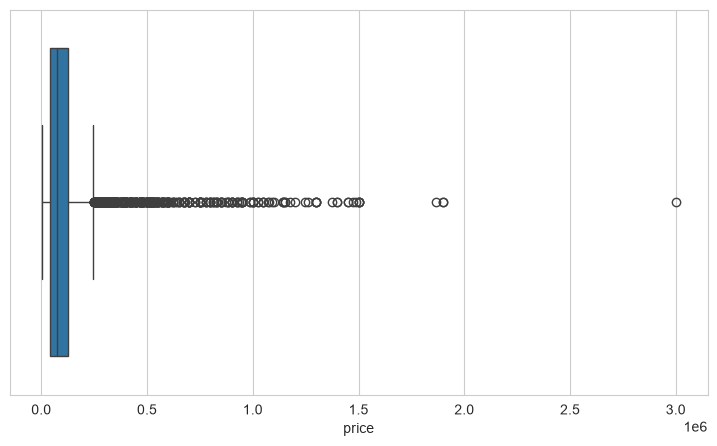

In [33]:
plt.figure(figsize=(9,5))
sns.boxplot(data=df_clean,x='price',)

In [34]:
df_clean['model_name']

0          Bajaj Avenger Cruise 220 2017
1       Royal Enfield Classic 350cc 2016
2                    Hyosung GT250R 2012
3             Bajaj Dominar 400 ABS 2017
4                  Jawa Perak 330cc 2020
                      ...               
7852           Yamaha YZF-R15 150cc 2011
7853           Bajaj Discover 100cc 2015
7854             Bajaj Pulsar 180cc 2016
7855                Bajaj V15 150cc 2016
7856             Bajaj Pulsar 220cc 2016
Name: model_name, Length: 7826, dtype: str

In [35]:
df_clean['model_name'].str.split()

0          [Bajaj, Avenger, Cruise, 220, 2017]
1       [Royal, Enfield, Classic, 350cc, 2016]
2                      [Hyosung, GT250R, 2012]
3             [Bajaj, Dominar, 400, ABS, 2017]
4                   [Jawa, Perak, 330cc, 2020]
                         ...                  
7852            [Yamaha, YZF-R15, 150cc, 2011]
7853            [Bajaj, Discover, 100cc, 2015]
7854              [Bajaj, Pulsar, 180cc, 2016]
7855                 [Bajaj, V15, 150cc, 2016]
7856              [Bajaj, Pulsar, 220cc, 2016]
Name: model_name, Length: 7826, dtype: object

In [37]:
df_clean['brand']=df_clean['model_name'].str.split().str[0]

In [38]:
df_clean

,model_name,model_year,kms_driven,owner,location,mileage,power,price,bike_age,brand
0,Bajaj Avenger Cruise 220 2017,True,17000.00,first owner,hyderabad,35.00,19.00,63500,2025,Bajaj
1,Royal Enfield Classic 350cc 2016,True,50000.00,first owner,hyderabad,35.00,1980.00,115000,2025,Royal
2,Hyosung GT250R 2012,True,14795.00,first owner,hyderabad,30.00,28.00,300000,2025,Hyosung
3,Bajaj Dominar 400 ABS 2017,True,28.00,first owner,pondicherry,28.00,3450.00,100000,2025,Bajaj
4,Jawa Perak 330cc 2020,True,2000.00,first owner,bangalore,NaN,30.00,197500,2025,Jawa
...,...,...,...,...,...,...,...,...,...,...
7852,Yamaha YZF-R15 150cc 2011,True,7000.00,first owner,agra,42.00,16.00,55000,2025,Yamaha
7853,Bajaj Discover 100cc 2015,True,80.00,first owner,delhi,80.00,77.00,28000,2025,Bajaj
7854,Bajaj Pulsar 180cc 2016,True,6407.00,first owner,bangalore,65.00,17.00,61740,2025,Bajaj
7855,Bajaj V15 150cc 2016,True,7524.00,first owner,bangalore,57.00,1180.00,49000,2025,Bajaj


In [39]:
df_clean['brand'].unique()

array(['Bajaj', 'Royal', 'Hyosung', 'Jawa', 'KTM', 'TVS', 'Yamaha',
       'Honda', 'UM', 'Hero', 'Suzuki', 'Husqvarna', 'Mahindra',
       'Harley-Davidson', 'Kawasaki', 'Benelli', 'Triumph', 'Ducati',
       'BMW', 'Ideal', 'BenelliImperiale', 'Moto', 'Fb', 'Indian',
       'Yazdi', 'Aprilia', 'MV', 'yamaha'], dtype=object)

In [40]:
df_clean['brand'].str.lower().unique()

array(['bajaj', 'royal', 'hyosung', 'jawa', 'ktm', 'tvs', 'yamaha',
       'honda', 'um', 'hero', 'suzuki', 'husqvarna', 'mahindra',
       'harley-davidson', 'kawasaki', 'benelli', 'triumph', 'ducati',
       'bmw', 'ideal', 'benelliimperiale', 'moto', 'fb', 'indian',
       'yazdi', 'aprilia', 'mv'], dtype=object)

In [41]:
df_clean['brand']=df_clean['model_name'].str.split().str[0].str.lower()

In [43]:
df_clean['brand']

0         bajaj
1         royal
2       hyosung
3         bajaj
4          jawa
         ...   
7852     yamaha
7853      bajaj
7854      bajaj
7855      bajaj
7856      bajaj
Name: brand, Length: 7826, dtype: object

In [45]:
df_clean.groupby('brand')['price'].agg(['median','mean','count'])

,median,mean,count
brand,,,
aprilia,1000000.00,1000000.00,2
bajaj,50000.00,57153.23,2098
benelli,260000.00,301581.89,53
benelliimperiale,213750.00,216910.33,6
bmw,274800.00,397860.00,10
ducati,907293.50,976293.69,16
fb,320850.00,320850.00,2
harley-davidson,450000.00,512722.60,171
hero,33840.00,38872.52,794


In [47]:
brand_stats=df_clean.groupby('brand')['price'].agg(['median','mean','count']).reset_index()

In [48]:
brand_stats

,brand,median,mean,count
0,aprilia,1000000.00,1000000.00,2
1,bajaj,50000.00,57153.23,2098
2,benelli,260000.00,301581.89,53
3,benelliimperiale,213750.00,216910.33,6
4,bmw,274800.00,397860.00,10
5,ducati,907293.50,976293.69,16
6,fb,320850.00,320850.00,2
7,harley-davidson,450000.00,512722.60,171
8,hero,33840.00,38872.52,794
9,honda,49749.50,70906.22,530


In [49]:
brand_stats[brand_stats['count']>10]

,brand,median,mean,count
1,bajaj,50000.00,57153.23,2098
2,benelli,260000.00,301581.89,53
5,ducati,907293.50,976293.69,16
7,harley-davidson,450000.00,512722.60,171
8,hero,33840.00,38872.52,794
9,honda,49749.50,70906.22,530
10,husqvarna,205000.00,206767.00,11
11,hyosung,198600.00,221660.19,52
14,jawa,165000.00,171286.13,46
15,kawasaki,465000.00,496517.70,67


In [50]:
brand_stats[brand_stats['count']>10].sort_values(by='median',ascending=False)

,brand,median,mean,count
5,ducati,907293.50,976293.69,16
22,triumph,800000.00,843183.25,36
15,kawasaki,465000.00,496517.70,67
7,harley-davidson,450000.00,512722.60,171
2,benelli,260000.00,301581.89,53
10,husqvarna,205000.00,206767.00,11
11,hyosung,198600.00,221660.19,52
14,jawa,165000.00,171286.13,46
16,ktm,147000.00,150354.56,491
24,um,125000.00,128446.01,128


In [53]:
brand_top_10=brand_stats[brand_stats['count']>10].sort_values(by='median',ascending=False).head(10)

<Axes: xlabel='brand', ylabel='median'>

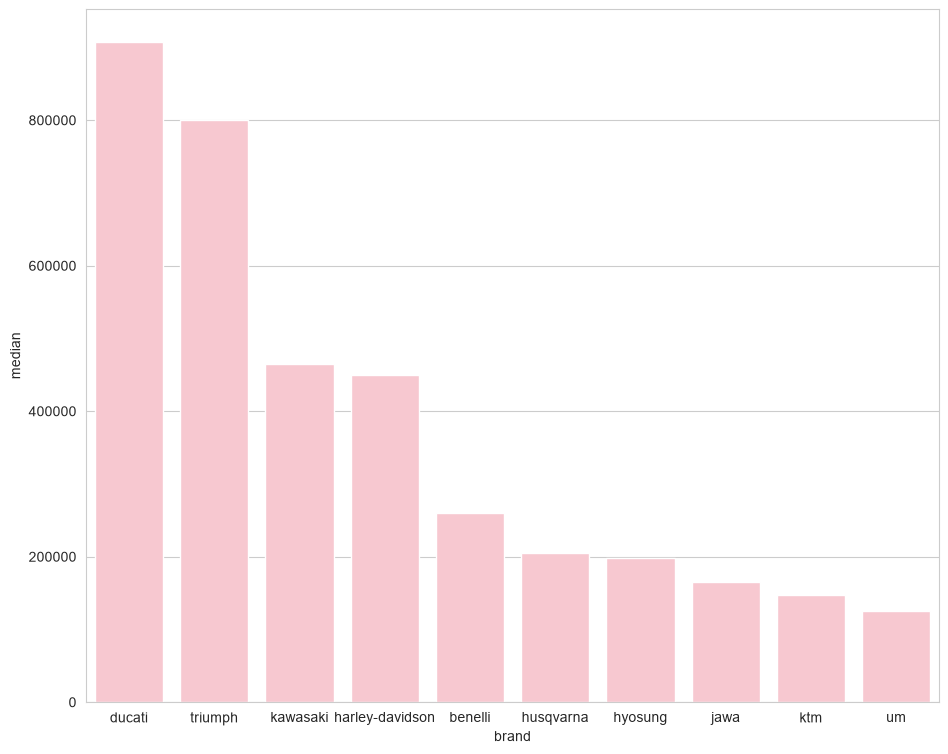

In [61]:
plt.figure(figsize=(11,9))
sns.barplot(data=brand_top_10,x='brand',y='median',color='pink')

In [62]:
df_clean

,model_name,model_year,kms_driven,owner,location,mileage,power,price,bike_age,brand
0,Bajaj Avenger Cruise 220 2017,True,17000.00,first owner,hyderabad,35.00,19.00,63500,2025,bajaj
1,Royal Enfield Classic 350cc 2016,True,50000.00,first owner,hyderabad,35.00,1980.00,115000,2025,royal
2,Hyosung GT250R 2012,True,14795.00,first owner,hyderabad,30.00,28.00,300000,2025,hyosung
3,Bajaj Dominar 400 ABS 2017,True,28.00,first owner,pondicherry,28.00,3450.00,100000,2025,bajaj
4,Jawa Perak 330cc 2020,True,2000.00,first owner,bangalore,NaN,30.00,197500,2025,jawa
...,...,...,...,...,...,...,...,...,...,...
7852,Yamaha YZF-R15 150cc 2011,True,7000.00,first owner,agra,42.00,16.00,55000,2025,yamaha
7853,Bajaj Discover 100cc 2015,True,80.00,first owner,delhi,80.00,77.00,28000,2025,bajaj
7854,Bajaj Pulsar 180cc 2016,True,6407.00,first owner,bangalore,65.00,17.00,61740,2025,bajaj
7855,Bajaj V15 150cc 2016,True,7524.00,first owner,bangalore,57.00,1180.00,49000,2025,bajaj


In [63]:
df_clean[['kms_driven','price']].corr()

,kms_driven,price
kms_driven,1.00,-0.11
price,-0.11,1.00


In [64]:
plot_data = df_clean.dropna(subset=['kms_driven','price'])

In [65]:
plot_data

,model_name,model_year,kms_driven,owner,location,mileage,power,price,bike_age,brand
0,Bajaj Avenger Cruise 220 2017,True,17000.00,first owner,hyderabad,35.00,19.00,63500,2025,bajaj
1,Royal Enfield Classic 350cc 2016,True,50000.00,first owner,hyderabad,35.00,1980.00,115000,2025,royal
2,Hyosung GT250R 2012,True,14795.00,first owner,hyderabad,30.00,28.00,300000,2025,hyosung
3,Bajaj Dominar 400 ABS 2017,True,28.00,first owner,pondicherry,28.00,3450.00,100000,2025,bajaj
4,Jawa Perak 330cc 2020,True,2000.00,first owner,bangalore,NaN,30.00,197500,2025,jawa
...,...,...,...,...,...,...,...,...,...,...
7852,Yamaha YZF-R15 150cc 2011,True,7000.00,first owner,agra,42.00,16.00,55000,2025,yamaha
7853,Bajaj Discover 100cc 2015,True,80.00,first owner,delhi,80.00,77.00,28000,2025,bajaj
7854,Bajaj Pulsar 180cc 2016,True,6407.00,first owner,bangalore,65.00,17.00,61740,2025,bajaj
7855,Bajaj V15 150cc 2016,True,7524.00,first owner,bangalore,57.00,1180.00,49000,2025,bajaj


<Axes: xlabel='kms_driven', ylabel='price'>

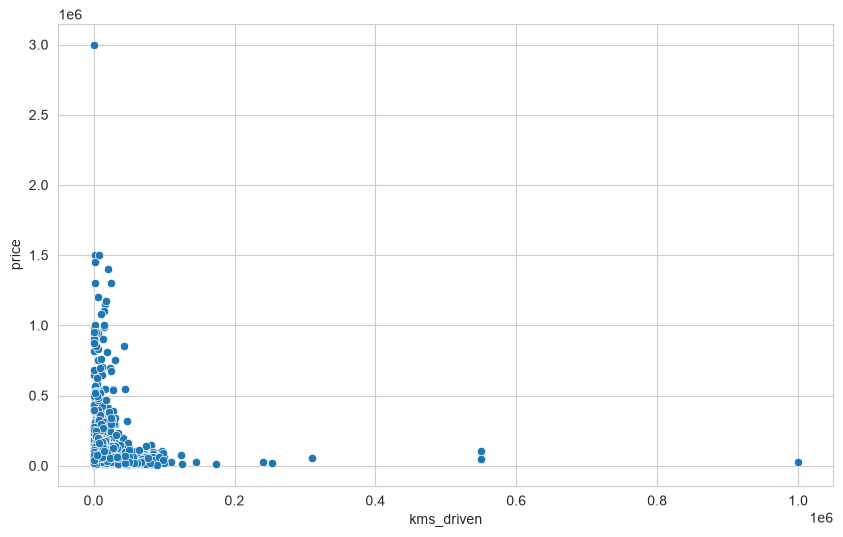

In [67]:
plot_data = df_clean.dropna(subset=['kms_driven','price'])
if len(plot_data)>3000:
    plot_data = plot_data.sample(3000,random_state=42)

plt.figure(figsize=(10,6))

sns.scatterplot(data=plot_data,x='kms_driven',y='price')

<Axes: xlabel='kms_driven', ylabel='price'>

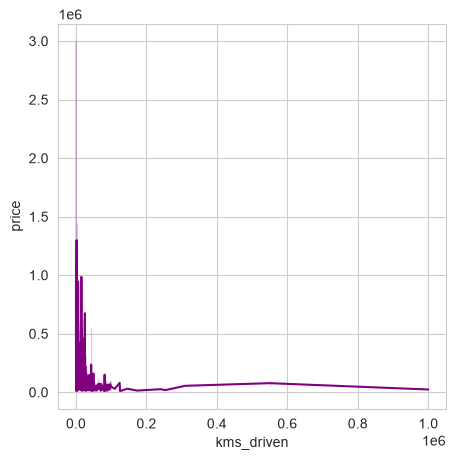

In [79]:
plot_data = df_clean.dropna(subset=['kms_driven','price'])
if len(plot_data)>3000:
    plot_data = plot_data.sample(3000,random_state=42)

plt.figure(figsize=(5,5))

sns.lineplot(data=plot_data,x='kms_driven',y='price',color='purple')

<Axes: xlabel='bike_age', ylabel='price'>

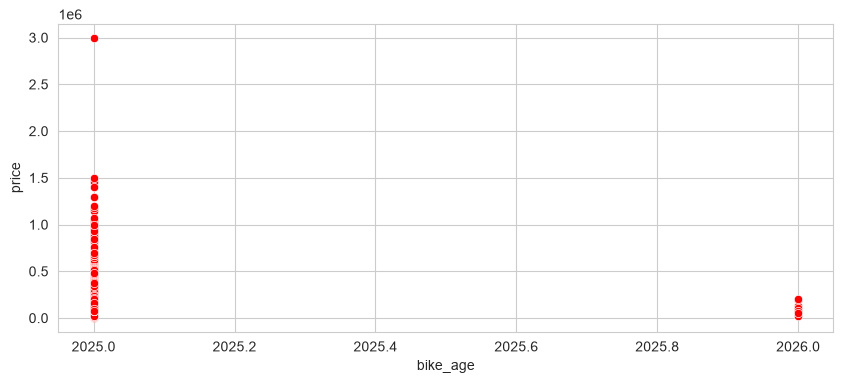

In [81]:
plot_data = df_clean.dropna(subset=['bike_age','price'])
if len(plot_data)>3000:
    plot_data = plot_data.sample(3000,random_state=42)

plt.figure(figsize=(10,4))

sns.scatterplot(data=plot_data,x='bike_age',y='price',color='red')

<Axes: >

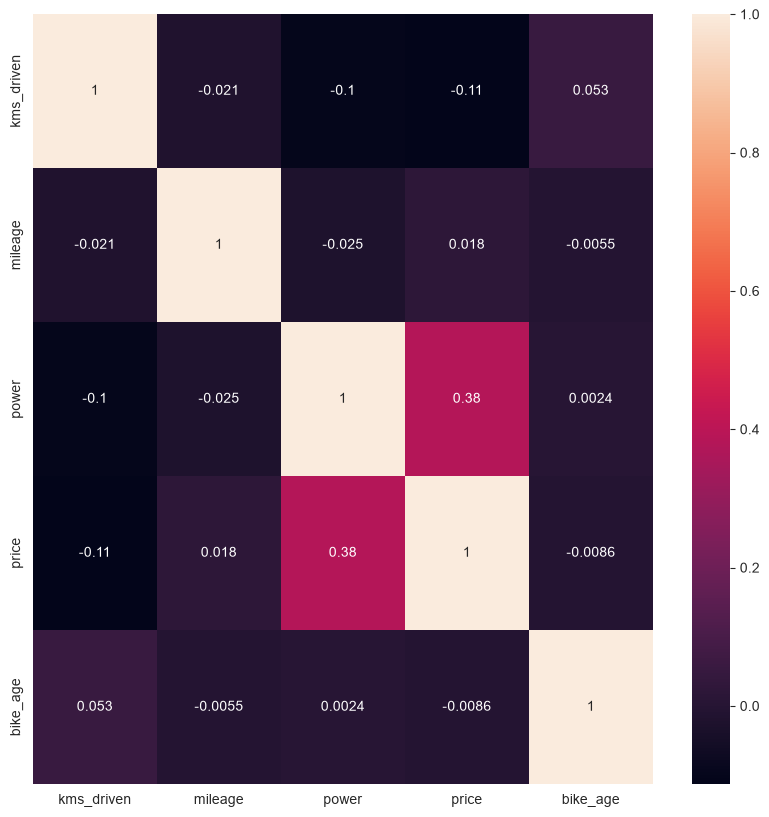

In [86]:
numeric_df=df_clean.select_dtypes(include='number')

plt.figure(figsize=(10,10))
sns.heatmap(numeric_df.corr(),annot=True)

In [87]:
df_clean.dropna(inplace=True)

C:\Users\HP\AppData\Local\Temp\ipykernel_10900\1832953665.py:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_clean.dropna(inplace=True)


In [88]:
df_clean

,model_name,model_year,kms_driven,owner,location,mileage,power,price,bike_age,brand
0,Bajaj Avenger Cruise 220 2017,True,17000.00,first owner,hyderabad,35.00,19.00,63500,2025,bajaj
1,Royal Enfield Classic 350cc 2016,True,50000.00,first owner,hyderabad,35.00,1980.00,115000,2025,royal
2,Hyosung GT250R 2012,True,14795.00,first owner,hyderabad,30.00,28.00,300000,2025,hyosung
3,Bajaj Dominar 400 ABS 2017,True,28.00,first owner,pondicherry,28.00,3450.00,100000,2025,bajaj
5,KTM Duke 200cc 2012,True,24561.00,third owner,bangalore,35.00,25.00,63400,2025,ktm
...,...,...,...,...,...,...,...,...,...,...
7852,Yamaha YZF-R15 150cc 2011,True,7000.00,first owner,agra,42.00,16.00,55000,2025,yamaha
7853,Bajaj Discover 100cc 2015,True,80.00,first owner,delhi,80.00,77.00,28000,2025,bajaj
7854,Bajaj Pulsar 180cc 2016,True,6407.00,first owner,bangalore,65.00,17.00,61740,2025,bajaj
7855,Bajaj V15 150cc 2016,True,7524.00,first owner,bangalore,57.00,1180.00,49000,2025,bajaj


In [90]:
df_clean.reset_index(inplace=True,drop='first')

C:\Users\HP\AppData\Local\Temp\ipykernel_10900\1442894773.py:1: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_clean.reset_index(inplace=True,drop='first')


In [91]:
df_clean

,index,model_name,model_year,kms_driven,owner,location,mileage,power,price,bike_age,brand
0,0,Bajaj Avenger Cruise 220 2017,True,17000.00,first owner,hyderabad,35.00,19.00,63500,2025,bajaj
1,1,Royal Enfield Classic 350cc 2016,True,50000.00,first owner,hyderabad,35.00,1980.00,115000,2025,royal
2,2,Hyosung GT250R 2012,True,14795.00,first owner,hyderabad,30.00,28.00,300000,2025,hyosung
3,3,Bajaj Dominar 400 ABS 2017,True,28.00,first owner,pondicherry,28.00,3450.00,100000,2025,bajaj
4,5,KTM Duke 200cc 2012,True,24561.00,third owner,bangalore,35.00,25.00,63400,2025,ktm
...,...,...,...,...,...,...,...,...,...,...,...
7025,7852,Yamaha YZF-R15 150cc 2011,True,7000.00,first owner,agra,42.00,16.00,55000,2025,yamaha
7026,7853,Bajaj Discover 100cc 2015,True,80.00,first owner,delhi,80.00,77.00,28000,2025,bajaj
7027,7854,Bajaj Pulsar 180cc 2016,True,6407.00,first owner,bangalore,65.00,17.00,61740,2025,bajaj
7028,7855,Bajaj V15 150cc 2016,True,7524.00,first owner,bangalore,57.00,1180.00,49000,2025,bajaj


In [92]:
data = df_clean.drop(['model_name','location'],axis=1)

In [93]:
data.columns

Index(['index', 'model_year', 'kms_driven', 'owner', 'mileage', 'power',
       'price', 'bike_age', 'brand'],
      dtype='str')

In [96]:
x = data[['model_year','kms_driven','owner', 'mileage','power','price',
            'bike_age','brand']]
y = data['price']

In [99]:
from sklearn.model_selection import train_test_split
x_train,x_test, y_train , y_test = train_test_split(x,y,random_state=42,test_size=0.2)

In [100]:
numerical_column =x.select_dtypes(include='number').columns
categorical_column =x.select_dtypes(exclude='number').columns


In [101]:
numeric_pipeline = Pipeline(steps=[('imputer',SimpleImputer(strategy='median'))])
categorical_column = Pipeline(steps=[('imputer',SimpleImputer(strategy='most_frequent')),
                                 ('ohe',OneHotEncoder(handle_unknown='ignore'))])

In [ ]:
transformer =[]
if numerical_column:
    transformer.append(numeric_pipeline)
if categorical_column:
    transformer.append(categorical_pipeline)